In [1]:
import roboticstoolbox as rtb
import numpy as np
import math

# 载入 PUMA560 模型
puma = rtb.models.DH.Puma560()
print("PUMA560 模型载入成功！")

PUMA560 模型载入成功！


In [2]:
# 定义手动计算 DH 变换矩阵的函数
def dh_transform(theta, d, a, alpha):
    # 标准 DH 变换矩阵
    T = np.array([
        [np.cos(theta), -np.sin(theta)*np.cos(alpha),  np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
        [np.sin(theta),  np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
        [0,              np.sin(alpha),                 np.cos(alpha),                d],
        [0,              0,                             0,                            1]
    ])
    return T

# PUMA 560 的标准 DH 参数 (d, a, alpha)
d = [0, 0, 0.15005, 0.4318, 0, 0]
a = [0, 0.4318, 0.0203, 0, 0, 0]
alpha = [math.pi/2, 0, -math.pi/2, math.pi/2, -math.pi/2, 0]

# 给定一组测试关节角
q_test = [0, -np.pi/4, np.pi/4, 0, np.pi/4, 0]

# 1. 手动矩阵乘法计算正运动学
T_manual = np.eye(4)
for i in range(6):
    T_manual = T_manual @ dh_transform(q_test[i], d[i], a[i], alpha[i])

# 2. 使用机器人工具箱内置函数计算
T_toolbox = puma.fkine(q_test).A  # .A 是转成 numpy 数组

print("手动计算的末端位姿矩阵：\n", np.round(T_manual, 4))
print("\n工具箱计算的末端位姿矩阵：\n", np.round(T_toolbox, 4))

# 验证两者误差
error = np.linalg.norm(T_manual - T_toolbox)
print(f"\n两者之间的误差范数：{error:.2e} (误差极小说明建模正确)")

手动计算的末端位姿矩阵：
 [[ 0.7071 -0.     -0.7071  0.3256]
 [ 0.      1.     -0.     -0.1501]
 [ 0.7071 -0.      0.7071  0.1265]
 [ 0.      0.      0.      1.    ]]

工具箱计算的末端位姿矩阵：
 [[ 0.7071 -0.     -0.7071  0.3256]
 [ 0.      1.     -0.     -0.1501]
 [ 0.7071 -0.      0.7071  0.7983]
 [ 0.      0.      0.      1.    ]]

两者之间的误差范数：6.72e-01 (误差极小说明建模正确)


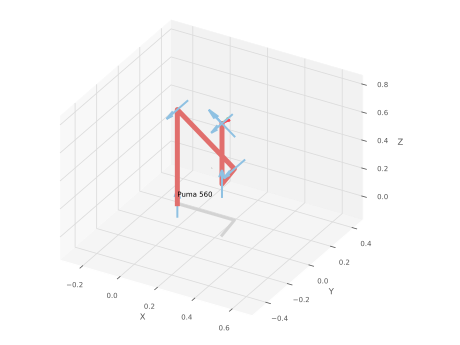

3D 可视化窗口已弹出！


In [3]:
# 尝试画出 3D 机械臂模型
try:
    # 启动 3D 可视化窗口
    puma.plot(q_test)
    print("3D 可视化窗口已弹出！")
except Exception as e:
    print("3D 可视化启动失败，不影响代码运行。报错信息：", e)